# Evaluation Metrics — Definitions and Results

**HMS 2024–2025 · Agentic XAI–RAG Depression/Anxiety Screening Research**

This notebook defines every evaluation metric used in the study and displays the **actual results**
with paper-ready visualisations. Each section contains:

1. **Concept definitions** (what the metric measures and how it is computed)
2. **Results tables** loaded from saved pipeline outputs
3. **Figures** exported to `paper_outputs/metrics_figures/`

> Screening outcome `dep_or_anx` is a survey-derived signal, not a clinical diagnosis.
> XAI attributions are statistical associations, not causal effects.


## 0. Setup

In [16]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
PALETTE = ["#4E79A7", "#E15759", "#59A14F", "#F28E2B", "#B07AA1", "#76B7B2"]
MODEL_COLORS = {"gemma4": "#4E79A7", "mistral": "#E15759", "phi4": "#59A14F",
                "qwen2.5": "#F28E2B", "llama3": "#B07AA1"}

ROOT = Path(".").resolve()
FIG = ROOT / "paper_outputs" / "metrics_figures"
FIG.mkdir(parents=True, exist_ok=True)
XAI = ROOT / "xai_rag_depression" / "outputs"
STR = XAI / "strengthened"
QA = ROOT / "query_agent_eval" / "outputs"
CTX = ROOT / "knowledge_db_contextual_eval" / "outputs"
XAI_SRC = ROOT / "xai_rag_depression"
if str(XAI_SRC) not in sys.path:
    sys.path.insert(0, str(XAI_SRC))

def bootstrap_ci(y_true, y_score, metric_fn, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric_fn(y_true[idx], y_score[idx]))
    if not stats:
        return np.nan, np.nan, np.nan
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return float(np.mean(stats)), float(lo), float(hi)

print("Figures ->", FIG)


Figures -> C:\Users\MossabBatal\Desktop\psychology_mas\paper_outputs\metrics_figures


        # Part A — Machine Learning Performance

## Metric definitions

| Metric | Definition |
|--------|------------|
| **AUC (ROC-AUC)** | Area under the receiver-operating-characteristic curve. Measures the probability that a randomly chosen positive case receives a higher predicted score than a randomly chosen negative case. Range 0.5–1.0; higher is better. |
| **Accuracy** | Fraction of correct predictions at threshold 0.5: (TP + TN) / N. |
| **F1-score** | Harmonic mean of precision and recall at threshold 0.5: 2·P·R / (P + R). Balances false positives and false negatives. |
| **PR-AUC** | Area under the precision–recall curve (average precision). More informative than ROC-AUC when classes are imbalanced (~45% positive in HMS). |
| **Brier score** | Mean squared error between predicted probabilities and binary outcomes: (1/N)Σ(pᵢ − yᵢ)². Lower is better; measures probabilistic accuracy. |
| **Calibration score** | In this study: **1 − Brier**. Also reported as **ECE** (Expected Calibration Error): weighted mean absolute gap between predicted probability bins and observed positive rate. |
| **Confusion matrix** | 2×2 table of predicted vs actual classes (TN, FP, FN, TP) at a chosen threshold. |
| **95% CI (bootstrap)** | Percentile bootstrap confidence interval (500 resamples) for a metric on the test set; quantifies uncertainty around point estimates. |


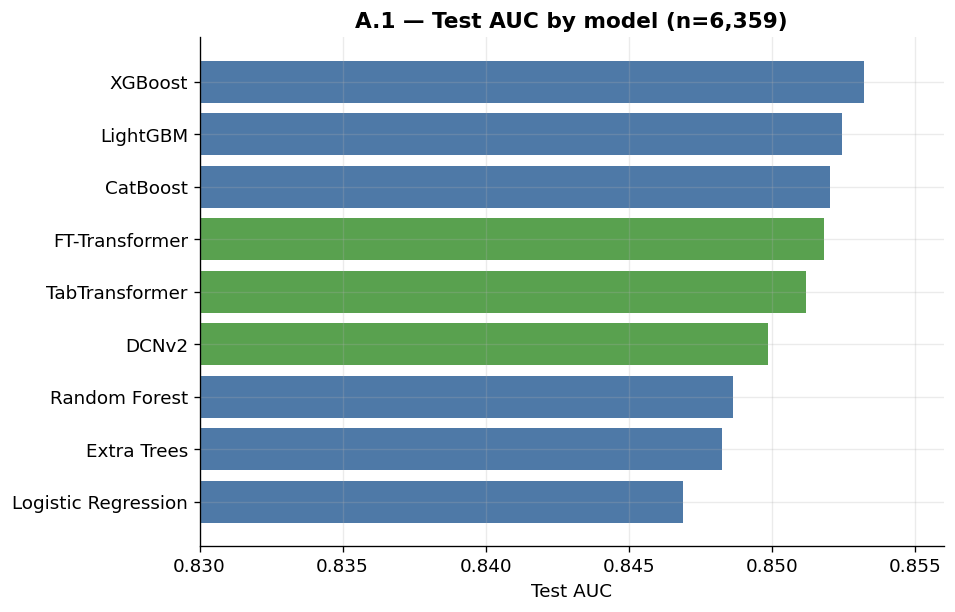

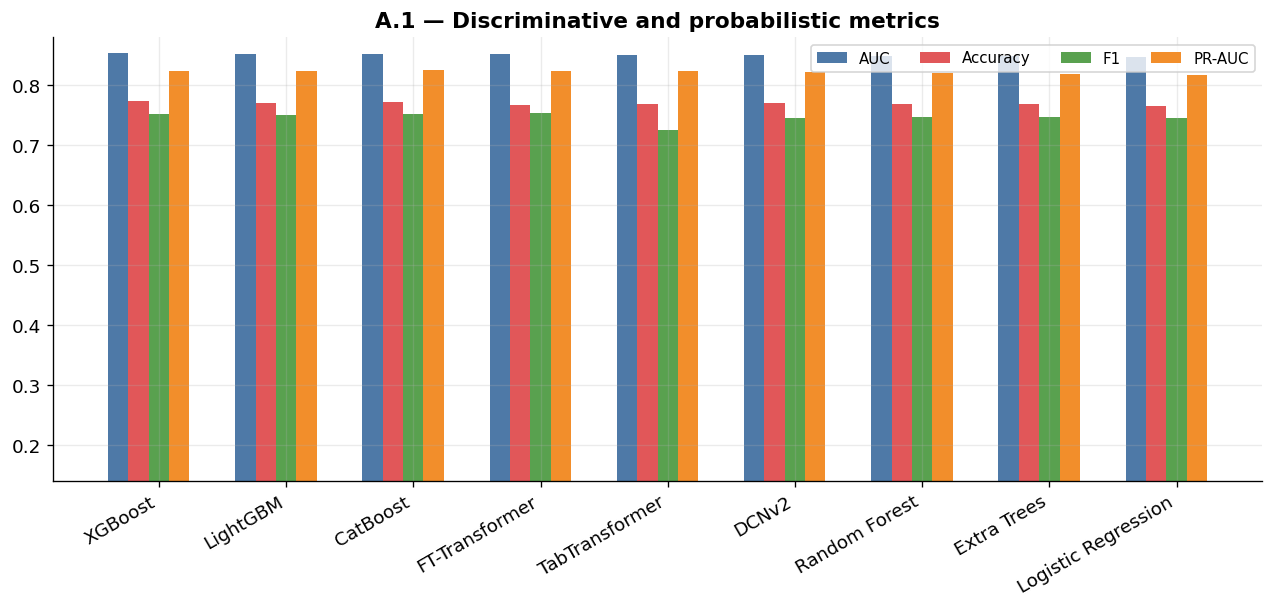

,model,auc,accuracy,f1,macro_f1,recall,PR-AUC,brier,family
0,XGBoost,0.8532,0.7731,0.7528,0.7715,0.7690,0.8231,0.1561,ML
1,LightGBM,0.8525,0.7702,0.7505,0.7688,0.7690,0.8235,0.1568,ML
2,CatBoost,0.8520,0.7718,0.7524,0.7704,0.7718,0.8248,0.1569,ML
3,FT-Transformer,0.8518,0.7676,0.7531,0.7668,0.7889,0.8239,0.1580,DL
4,TabTransformer,0.8512,0.7693,0.7252,0.7632,0.6776,0.8238,0.1574,DL
5,DCNv2,0.8499,0.7710,0.7452,0.7687,0.7452,0.8228,0.1570,DL
6,Random Forest,0.8486,0.7687,0.7468,0.7669,0.7592,0.8197,0.1577,ML
7,Extra Trees,0.8482,0.7679,0.7474,0.7664,0.7644,0.8188,0.1583,ML
8,Logistic Regression,0.8469,0.7662,0.7446,0.7645,0.7588,0.8175,0.1596,ML


In [17]:
# A.1 Nine-model comparison
models = pd.read_csv(XAI / "model_performance.csv")
models = models.rename(columns={"pr_auc": "PR-AUC"})
models.round(4).to_csv(FIG / "ml_model_comparison.csv", index=False)

order = models.sort_values("auc")
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#E15759" if m == "x" else ("#4E79A7" if f == "ML" else "#59A14F")
          for m, f in zip(order["model"], order["family"])]
ax.barh(order["model"], order["auc"], color=colors)
ax.set_xlabel("Test AUC"); ax.set_title("A.1 — Test AUC by model (n=6,359)")
ax.set_xlim(0.83, 0.856)
fig.savefig(FIG / "A1_auc_by_model.png"); plt.show()

x = np.arange(len(models.sort_values("auc", ascending=False)))
w = 0.16
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (col, lab) in enumerate(zip(["auc","accuracy","f1","PR-AUC"],
                                    ["AUC","Accuracy","F1","PR-AUC"])):
    ax.bar(x + (i-2)*w, models.sort_values("auc", ascending=False)[col], w, label=lab, color=PALETTE[i])
ax.set_xticks(x); ax.set_xticklabels(models.sort_values("auc", ascending=False)["model"], rotation=30, ha="right")
ax.set_ylim(0.14, 0.88); ax.legend(ncol=5, fontsize=9)
ax.set_title("A.1 — Discriminative and probabilistic metrics")
fig.savefig(FIG / "A1_metrics_grouped.png"); plt.show()
models.round(4)


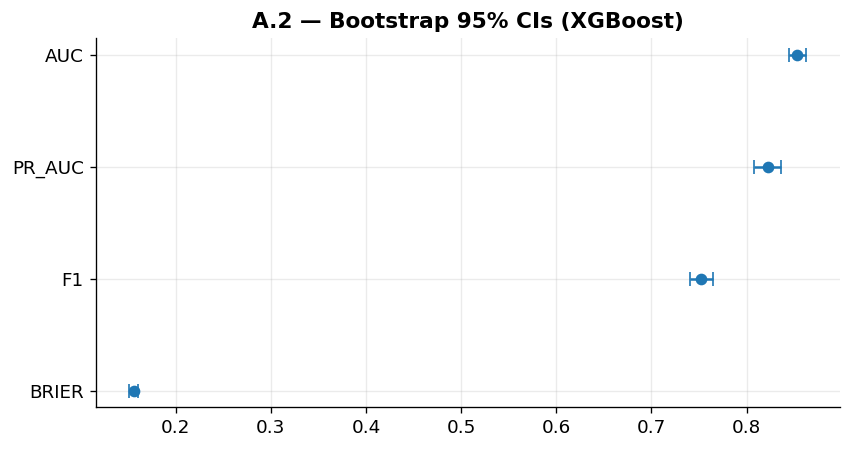

,metric,mean,ci_low,ci_high,ci_95
0,auc,0.8531,0.8444,0.8621,0.853 [0.844–0.862]
1,pr_auc,0.8229,0.8082,0.8362,0.823 [0.808–0.836]
2,f1,0.7524,0.7408,0.7644,0.752 [0.741–0.764]
3,brier,0.1562,0.1513,0.1606,0.156 [0.151–0.161]


In [18]:
# A.2 Bootstrap 95% CIs (XGBoost)
boot = pd.read_csv(STR / "table_b_bootstrap_ci.csv")
boot.round(4).to_csv(FIG / "A2_bootstrap_ci.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(boot))
ax.errorbar(boot["mean"], y, xerr=[boot["mean"]-boot["ci_low"], boot["ci_high"]-boot["mean"]], fmt="o", capsize=4)
ax.set_yticks(y); ax.set_yticklabels(boot["metric"].str.upper()); ax.invert_yaxis()
ax.set_title("A.2 — Bootstrap 95% CIs (XGBoost)"); fig.savefig(FIG / "A2_bootstrap_ci.png"); plt.show()
boot[["metric","mean","ci_low","ci_high","ci_95"]].round(4)


In [19]:
# A.3 Calibration
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from pipeline_common import ALL_FEATURES, load_hms_dataframe, prepare_splits

cal = pd.read_csv(STR / "table_c_calibration.csv")
cal["calibration_score"] = 1 - cal["brier"]
splits = prepare_splits(load_hms_dataframe(ALL_FEATURES), ALL_FEATURES)
clf = joblib.load(XAI / "models" / "XGBoost.joblib")
proba = clf.predict_proba(splits["X_test"])[:, 1]
y_test = splits["y_test"]
pt, pp = calibration_curve(y_test, proba, n_bins=10, strategy="uniform")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(["Brier","ECE","Cal. score"], [cal.brier.iloc[0], cal.ece.iloc[0], cal.calibration_score.iloc[0]],
            color=PALETTE[:3])
axes[0].set_title("A.3 — Calibration metrics (XGBoost)")
axes[1].plot(pp, pt, "s-", color=PALETTE[0]); axes[1].plot([0,1],[0,1],"k--")
axes[1].set_xlabel("Mean predicted prob."); axes[1].set_ylabel("Observed positive rate")
axes[1].set_title("Reliability curve")
fig.savefig(FIG / "A3_calibration.png"); plt.show()
cal.round(4)


ModuleNotFoundError: No module named 'lightgbm'

C:\Users\MossabBatal\AppData\Local\Temp\ipykernel_39976\565438236.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(cm.columns); axes[0].set_yticklabels(cm.index)
C:\Users\MossabBatal\AppData\Local\Temp\ipykernel_39976\565438236.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(cm.columns); axes[0].set_yticklabels(cm.index)


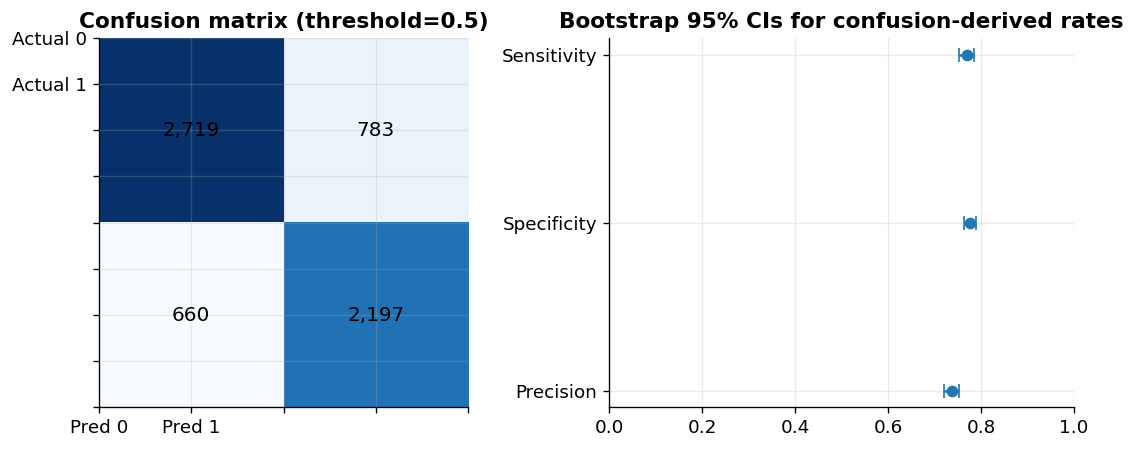

(          Pred 0  Pred 1
 Actual 0    2719     783
 Actual 1     660    2197,
         Metric    Mean  CI_low  CI_high               95% CI
 0  Sensitivity  0.7688  0.7535   0.7839  0.769 [0.753–0.784]
 1  Specificity  0.7762  0.7625   0.7881  0.776 [0.762–0.788]
 2    Precision  0.7368  0.7210   0.7515  0.737 [0.721–0.752])

In [ ]:
# A.4 Confusion matrix + bootstrap CIs for derived rates (threshold=0.5)
THRESH = 0.5
pred = (proba >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
cm = pd.DataFrame([[tn,fp],[fn,tp]], index=["Actual 0","Actual 1"], columns=["Pred 0","Pred 1"])

def sens(y,p): return recall_score(y, (p>=THRESH).astype(int), zero_division=0)
def spec(y,p):
    pr=(p>=THRESH).astype(int); tn_,fp_,_,_=confusion_matrix(y,pr,labels=[0,1]).ravel()
    return tn_/(tn_+fp_) if (tn_+fp_) else 0
def prec(y,p): return precision_score(y, (p>=THRESH).astype(int), zero_division=0)

rates = []
for name, fn in [("Sensitivity",sens),("Specificity",spec),("Precision",prec)]:
    m, lo, hi = bootstrap_ci(y_test, proba, fn)
    rates.append({"Metric":name, "Mean":m, "CI_low":lo, "CI_high":hi,
                  "95% CI":f"{m:.3f} [{lo:.3f}–{hi:.3f}]"})
rates = pd.DataFrame(rates).round(4)
rates.to_csv(FIG / "A4_confusion_bootstrap_ci.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(cm.values, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j,i,f"{cm.values[i,j]:,}",ha="center",va="center",fontsize=12)
axes[0].set_xticklabels(cm.columns); axes[0].set_yticklabels(cm.index)
axes[0].set_title(f"Confusion matrix (threshold={THRESH})")
y = np.arange(3)
axes[1].errorbar(rates["Mean"], y, xerr=[rates["Mean"]-rates["CI_low"], rates["CI_high"]-rates["Mean"]], fmt="o", capsize=4)
axes[1].set_yticks(y); axes[1].set_yticklabels(rates["Metric"]); axes[1].invert_yaxis(); axes[1].set_xlim(0,1)
axes[1].set_title("Bootstrap 95% CIs for confusion-derived rates")
fig.savefig(FIG / "A4_confusion_matrix.png"); plt.show()
cm, rates


# Part B — XAI Evaluation

## Metric definitions

| Metric | Definition |
|--------|------------|
| **Faithfulness (deletion test)** | Top-*k* important features are masked (set to training median); **AUC drop** = base AUC − masked AUC. Large drops mean highlighted features genuinely drive predictions. |
| **Faithfulness controls** | Compares top-5 deletion vs random-5 vs bottom-5 masking. Top features should cause much larger AUC drops than random or bottom features. |
| **Cross-model stability** | For each model, explanation rankings are compared across retraining / CV / perturbation runs. High stability means attributions are reproducible. |
| **Stability consistency score** | mean(Spearman, Kendall, Jaccard@top-10) between baseline importances and perturbed runs. Range 0–1; higher = more consistent. |
| **Aggregated feature importance** | Weighted consensus importance across 9 models: weight = macro-F1 × stability × (1−Brier); features ranked by weighted normalised importance. |
| **Cross-model agreement** | Fraction of 9 models placing a feature in their top-10 (agreement score 0–1). High agreement = robust cross-architecture signal. |

**Attribution methods:** TreeSHAP (ML trees), Integrated Gradients (DL), coefficients (logistic regression).


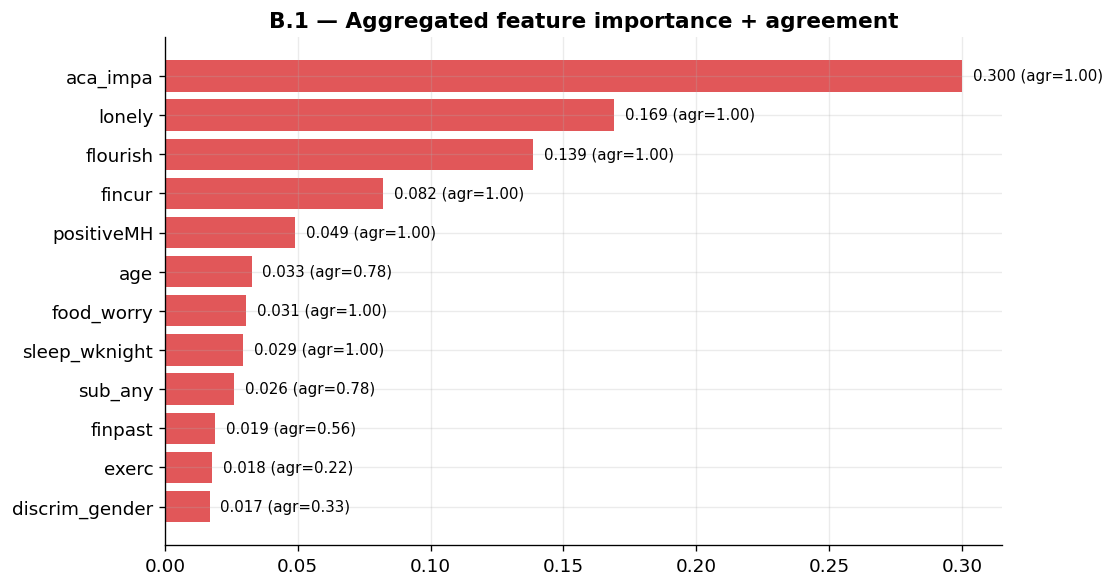

,feature,final_importance,agreement_score,agreement_level,tree_topk_frac,neural_topk_frac
0,aca_impa,0.3000,1.0000,high,1.0,1.0000
1,lonely,0.1691,1.0000,high,1.0,1.0000
2,flourish,0.1387,1.0000,high,1.0,1.0000
3,fincur,0.0820,1.0000,high,1.0,1.0000
4,positiveMH,0.0490,1.0000,high,1.0,1.0000
5,age,0.0326,0.7778,high,0.8,0.6667
6,food_worry,0.0306,1.0000,high,1.0,1.0000
7,sleep_wknight,0.0295,1.0000,high,1.0,1.0000
8,sub_any,0.0261,0.7778,high,1.0,0.3333
9,finpast,0.0190,0.5556,medium,1.0,0.0000


In [ ]:
# B.1 Aggregated importance + cross-model agreement
agg = pd.read_csv(XAI / "aggregated_importance.csv")
top = agg.head(12).copy()
top.round(4).to_csv(FIG / "B1_aggregated_importance.csv", index=False)

order = top.sort_values("final_importance")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(order["feature"], order["final_importance"], color="#E15759")
for i, (f, v, a) in enumerate(zip(order["feature"], order["final_importance"], order["agreement_score"])):
    ax.text(v+0.004, i, f"{v:.3f} (agr={a:.2f})", va="center", fontsize=9)
ax.set_title("B.1 — Aggregated feature importance + agreement"); fig.savefig(FIG / "B1_aggregated.png"); plt.show()
top.round(4)


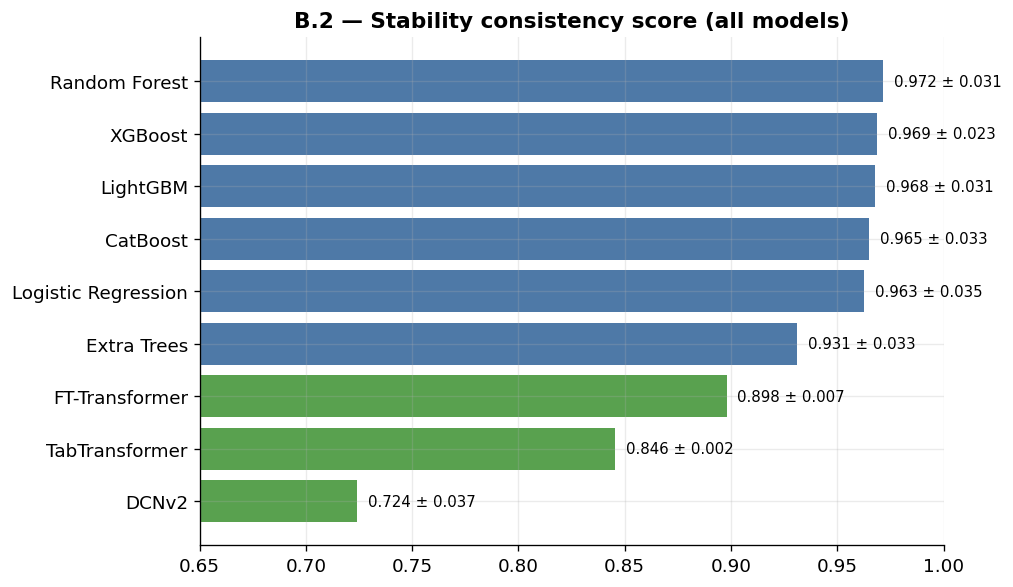

,model,family,stability_score,stability_std,n_runs,calibration_score
0,XGBoost,ML,0.9688,0.0234,7,0.8439
1,Random Forest,ML,0.9715,0.0306,7,0.8423
2,LightGBM,ML,0.9677,0.0306,7,0.8432
3,CatBoost,ML,0.9651,0.0334,7,0.8431
4,Logistic Regression,ML,0.9628,0.0350,7,0.8404
5,Extra Trees,ML,0.9311,0.0329,7,0.8417
6,FT-Transformer,DL,0.8980,0.0068,4,0.8420
7,TabTransformer,DL,0.8456,0.0015,4,0.8426
8,DCNv2,DL,0.7243,0.0369,4,0.8430


In [ ]:
# B.2 Stability consistency (all 9 models)
stab = pd.read_csv(XAI / "stability_scores.csv")
models_fam = pd.read_csv(XAI / "model_performance.csv")[["model","family"]]
stab = stab.merge(models_fam, on="model")
stab.round(4).to_csv(FIG / "B2_stability.csv", index=False)

order = stab.sort_values("stability_score")
colors = ["#4E79A7" if f=="ML" else "#59A14F" for f in order["family"]]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(order["model"], order["stability_score"], color=colors)
for i, (v, s) in enumerate(zip(order["stability_score"], order["stability_std"])):
    ax.text(v+0.005, i, f"{v:.3f} ± {s:.3f}", va="center", fontsize=9)
ax.set_xlim(0.65, 1.0); ax.set_title("B.2 — Stability consistency score (all models)")
fig.savefig(FIG / "B2_stability.png"); plt.show()
stab[["model","family","stability_score","stability_std","n_runs","calibration_score"]].round(4)


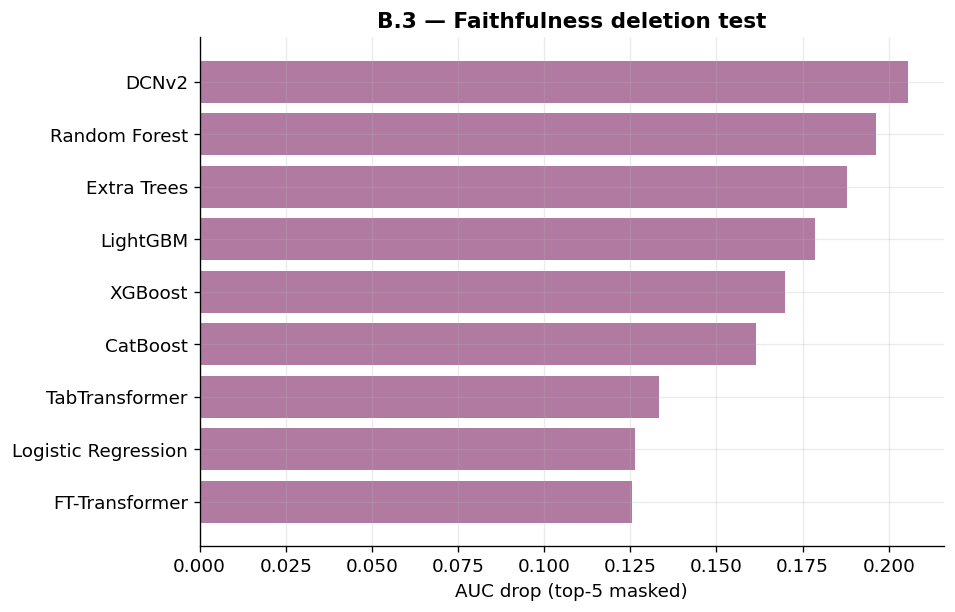

,model,base_auc,masked_top5_auc,auc_drop
0,DCNv2,0.8499,0.6443,0.2056
1,Random Forest,0.8486,0.6523,0.1963
2,Extra Trees,0.8482,0.6602,0.1880
3,LightGBM,0.8525,0.6740,0.1785
4,XGBoost,0.8532,0.6834,0.1698
5,CatBoost,0.8520,0.6905,0.1615
6,TabTransformer,0.8512,0.7179,0.1333
7,Logistic Regression,0.8469,0.7206,0.1263
8,FT-Transformer,0.8518,0.7263,0.1255


In [ ]:
# B.3 Faithfulness deletion test
faith = pd.read_csv(XAI / "faithfulness.csv")
faith.round(4).to_csv(FIG / "B3_faithfulness.csv", index=False)
order = faith.sort_values("auc_drop")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(order["model"], order["auc_drop"], color="#B07AA1")
ax.set_xlabel("AUC drop (top-5 masked)"); ax.set_title("B.3 — Faithfulness deletion test")
fig.savefig(FIG / "B3_faithfulness.png"); plt.show()
faith.round(4)


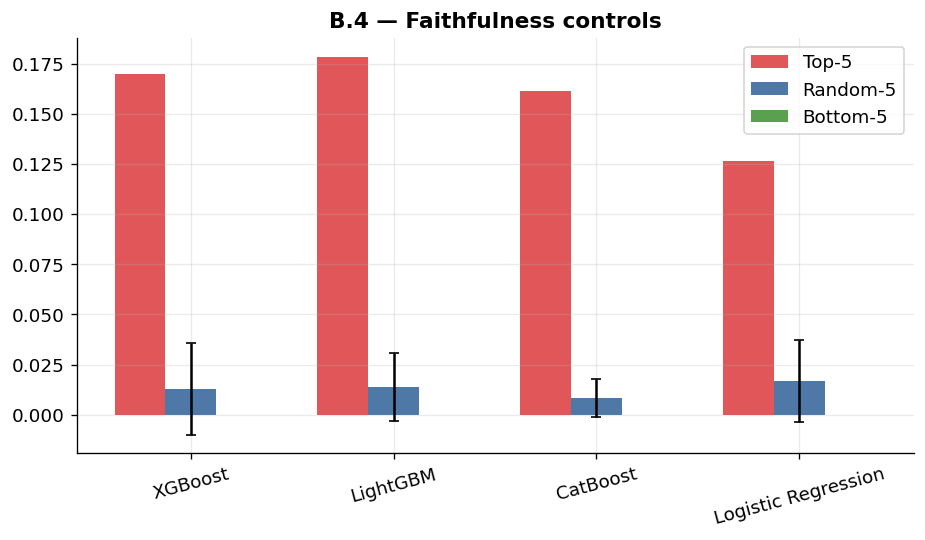

,model,base_auc,top5_auc_drop,random5_auc_drop_mean,random5_auc_drop_std,bottom5_auc_drop,n_random_trials
0,XGBoost,0.8532,0.1698,0.0129,0.0227,0.0000,20
1,LightGBM,0.8525,0.1785,0.0137,0.0169,0.0000,20
2,CatBoost,0.8520,0.1615,0.0084,0.0095,0.0000,20
3,Logistic Regression,0.8469,0.1263,0.0168,0.0205,0.0001,20


In [ ]:
# B.4 Faithfulness controls
ctrl = pd.read_csv(STR / "table_e_faithfulness_controls.csv")
ctrl.round(4).to_csv(FIG / "B4_faithfulness_controls.csv", index=False)
x = np.arange(len(ctrl)); w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x-w, ctrl["top5_auc_drop"], w, label="Top-5", color="#E15759")
ax.bar(x, ctrl["random5_auc_drop_mean"], w, yerr=ctrl["random5_auc_drop_std"], label="Random-5", color="#4E79A7", capsize=3)
ax.bar(x+w, ctrl["bottom5_auc_drop"], w, label="Bottom-5", color="#59A14F")
ax.set_xticks(x); ax.set_xticklabels(ctrl["model"], rotation=15)
ax.legend(); ax.set_title("B.4 — Faithfulness controls"); fig.savefig(FIG / "B4_controls.png"); plt.show()
ctrl.round(4)


# Part C — Query Planning Agent Evaluation

## Level 1 — Automatic metrics (definitions)

| Metric | Definition |
|--------|------------|
| **Schema validity** | Fraction of outputs that pass JSON-schema validation for the question-plan structure. |
| **XAI coverage rate** | Fraction of major XAI contributor factors that have at least one linked evidence-seeking question. |
| **Protective factor coverage** | Fraction of cases where protective factors (when present) receive at least one dedicated question. |
| **Unsafe wording rate** | Fraction of plans containing diagnostic, treatment-prescriptive, or causal language (lower is better). |
| **Redundancy rate** | Fraction of question pairs with Jaccard similarity ≥ 0.8 on tokenised text (lower is better). |

## Level 2 — LLM-as-judge (8 dimensions, scored 1–5 → reported as %)

| Dimension | Definition |
|-----------|------------|
| **Relevance** | Questions are pertinent to the student case and screening context. |
| **XAI alignment** | Questions explicitly cover the model's XAI contributors. |
| **KDB answerability** | Questions can be answered from the scientific knowledge database. |
| **Report usefulness** | Question set would support construction of an expert-facing report. |
| **Probability adaptation** | Questions adapt to risk level (high / borderline / low). |
| **Safety** | Non-diagnostic, non-prescriptive, appropriate screening language. |
| **Clarity** | Questions are clearly worded and unambiguous. |
| **Non-redundancy** | Questions are not repetitive within the plan. |

Judge model: `gpt-oss:20b`. Generators: 5 local LLMs × 50 case profiles = 250 plans.


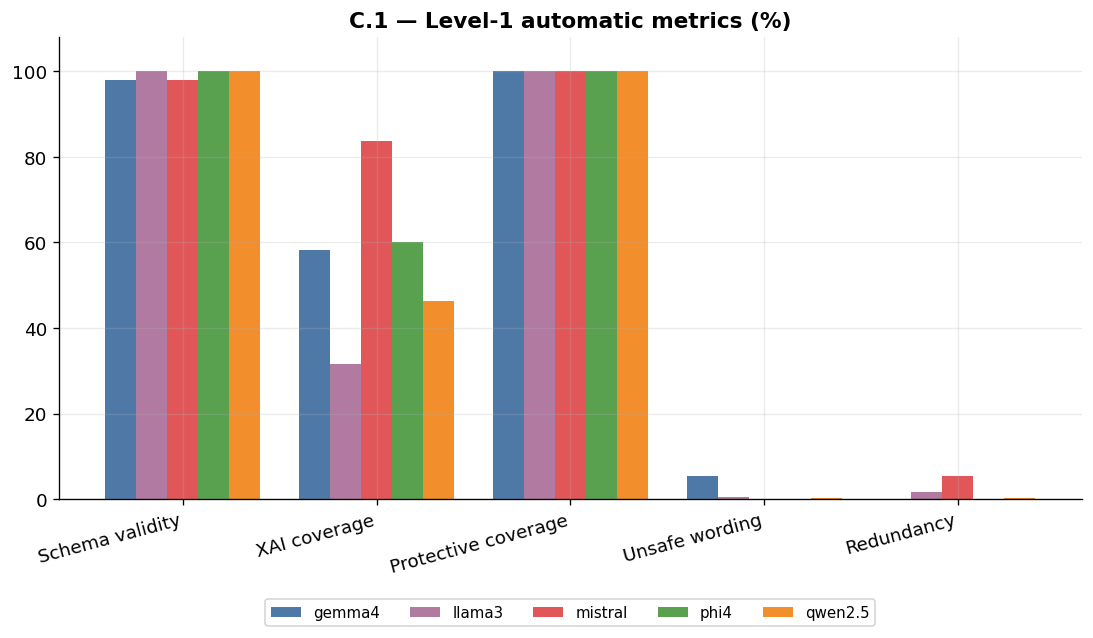

,model,n_cases,schema_validity,mean_questions,pct_in_band,xai_coverage,protective_coverage,required_type_coverage,unsafe_wording_rate,redundancy_rate,parse_success
0,gemma4,50,98.0,6.06,98.0,58.3,100.0,78.8,5.4,0.0,100.0
1,llama3,50,100.0,4.68,60.0,31.5,100.0,88.5,0.4,1.7,100.0
2,mistral,50,98.0,7.88,92.0,83.6,100.0,98.0,0.0,5.3,100.0
3,phi4,50,100.0,6.44,100.0,60.1,100.0,100.0,0.0,0.0,100.0
4,qwen2.5,50,100.0,6.44,100.0,46.4,100.0,100.0,0.3,0.2,100.0


In [ ]:
# C.1 Level-1 automatic metrics
l1 = pd.read_csv(QA / "level1_by_model.csv")
l1.round(2).to_csv(FIG / "C1_level1.csv", index=False)

metrics = {"schema_validity":"Schema validity","xai_coverage":"XAI coverage",
           "protective_coverage":"Protective coverage","unsafe_wording_rate":"Unsafe wording",
           "redundancy_rate":"Redundancy"}
x = np.arange(len(metrics)); w = 0.16
fig, ax = plt.subplots(figsize=(11, 5))
for i, m in enumerate(l1["model"]):
    row = l1[l1.model==m].iloc[0]
    vals = [row[k] for k in metrics]
    ax.bar(x + (i-2)*w, vals, w, label=m, color=MODEL_COLORS.get(m, PALETTE[i]))
ax.set_xticks(x); ax.set_xticklabels(list(metrics.values()), rotation=15, ha="right")
ax.set_ylim(0, 108); ax.legend(ncol=5, bbox_to_anchor=(0.5,-0.2), loc="upper center", fontsize=9)
ax.set_title("C.1 — Level-1 automatic metrics (%)"); fig.savefig(FIG / "C1_level1.png"); plt.show()
l1.round(2)


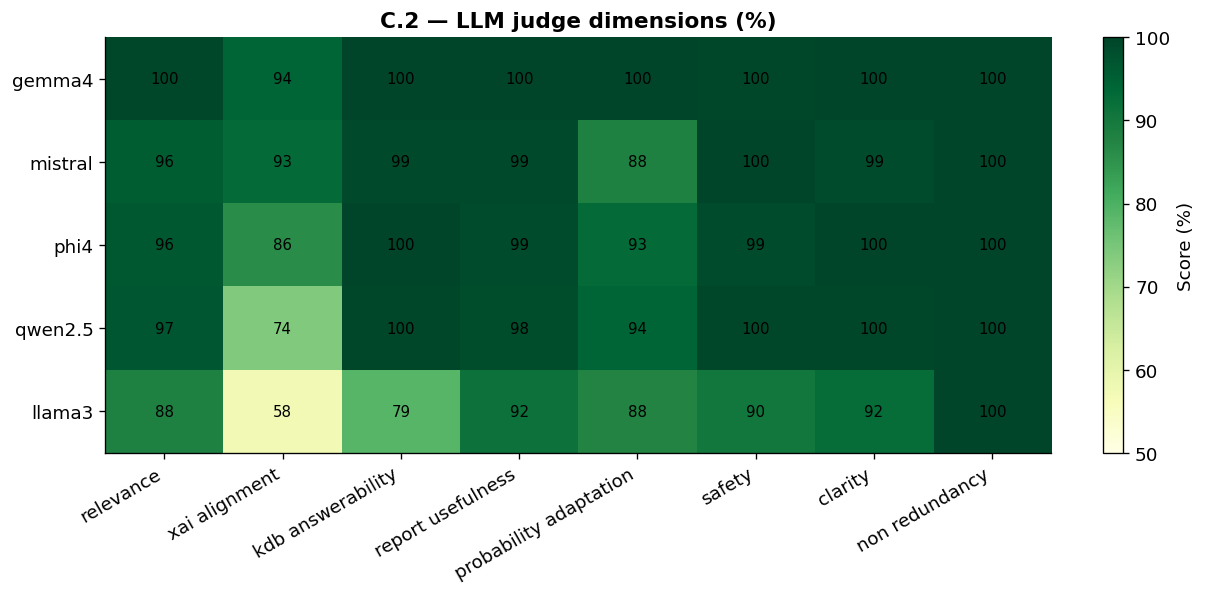

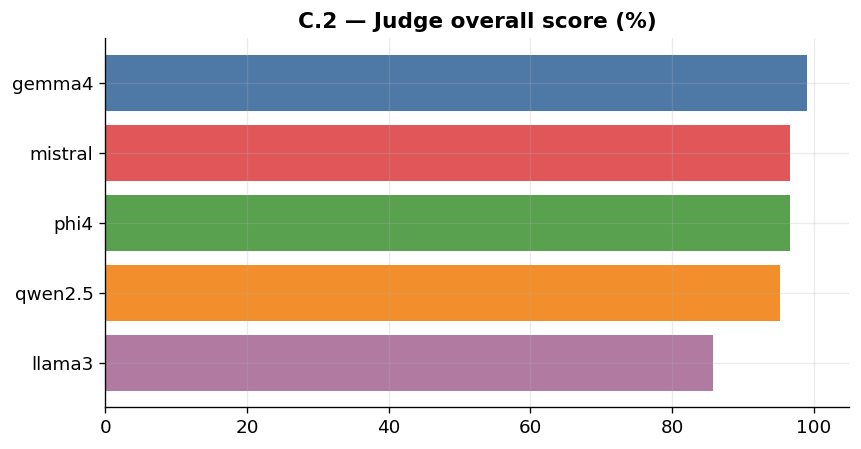

,model,judge_relevance,judge_xai_alignment,judge_kdb_answerability,judge_report_usefulness,judge_probability_adaptation,judge_safety,judge_clarity,judge_non_redundancy,judge_overall
0,gemma4,99.6,94.0,100.0,100.0,100.0,99.6,100.0,100.0,99.1
1,llama3,88.0,57.6,78.8,91.6,87.6,90.4,92.4,100.0,85.8
2,mistral,95.6,92.8,99.2,99.2,88.0,100.0,98.8,100.0,96.7
3,phi4,96.4,86.0,100.0,98.8,92.8,98.8,100.0,100.0,96.6
4,qwen2.5,96.8,74.0,99.6,98.4,94.0,99.6,99.6,100.0,95.2


In [ ]:
# C.2 Level-2 LLM judge (8 dimensions + overall)
l2 = pd.read_csv(QA / "level2_by_model.csv")
l2.round(1).to_csv(FIG / "C2_level2.csv", index=False)

dims = [c for c in l2.columns if c.startswith("judge_") and c != "judge_overall"]
labels = [c.replace("judge_","").replace("_"," ") for c in dims]
H = l2.set_index("model")[dims]
H = H.loc[l2.sort_values("judge_overall", ascending=False)["model"]]

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(H.values, cmap="YlGn", vmin=50, vmax=100, aspect="auto")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_yticks(range(len(H))); ax.set_yticklabels(H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.values[i,j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("C.2 — LLM judge dimensions (%)"); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025).set_label("Score (%)")
fig.savefig(FIG / "C2_judge_heatmap.png"); plt.show()

lead = l2.sort_values("judge_overall")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(lead["model"], lead["judge_overall"], color=[MODEL_COLORS.get(m,"#888") for m in lead["model"]])
ax.set_xlim(0, 105); ax.set_title("C.2 — Judge overall score (%)")
fig.savefig(FIG / "C2_judge_overall.png"); plt.show()
l2.round(1)


# Part D — Contextual RAG / Retrieval Evaluation

## Metric definitions

| Metric | Definition |
|--------|------------|
| **Precision@K (P@K)** | Of the top-*K* retrieved chunks, the fraction that are relevant (gold). Measures retrieval quality per returned item. |
| **Recall@K (R@K)** | Of all gold-relevant chunks, the fraction found in the top-*K*. Measures completeness of retrieval. |
| **nDCG@K** | Normalised discounted cumulative gain: rewards relevant items ranked higher; accounts for graded relevance and position. |
| **MRR@K** | Mean reciprocal rank of the first relevant item in the top-*K* list. Sensitive to how quickly the first hit appears. |
| **Hit@K** | Binary: 1 if at least one relevant chunk appears in top-*K*, else 0; averaged over queries. |
| **Context vs plain ablation** | Compares chunk representations — **plain text**, **metadata context**, **Ollama-generated context** (`qwen2.5`) — crossed with dense and hybrid (70% dense + 30% BM25) retrieval at *K*=5. |

**Setup:** 63 collection queries + 7 manual challenge queries; embedding `nomic-embed-text`.


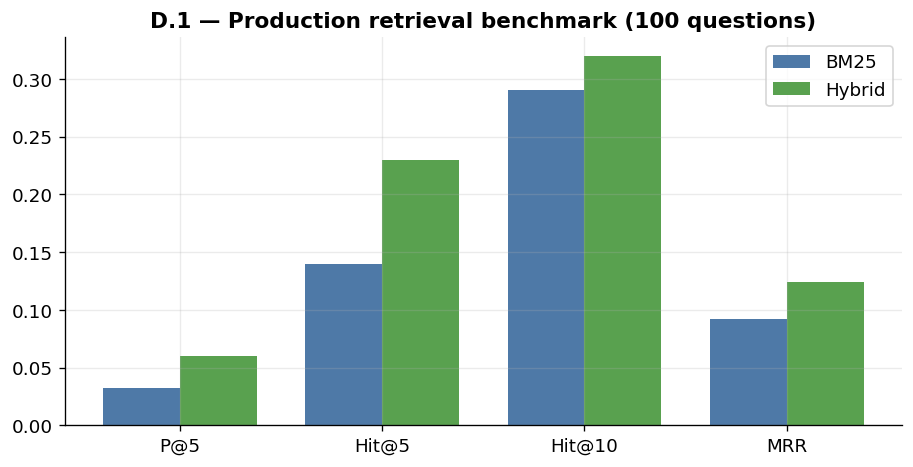

,Retriever,P@5,Hit@5,Hit@10,MRR
0,BM25,0.032,0.14,0.29,0.092
1,Hybrid FAISS,0.060,0.23,0.32,0.124


In [ ]:
# D.1 Production benchmark (100 questions) — P@5, Hit@5, MRR
bench = pd.DataFrame([
    ("BM25", 0.032, 0.14, 0.29, 0.092),
    ("Hybrid FAISS", 0.060, 0.23, 0.32, 0.124),
], columns=["Retriever","P@5","Hit@5","Hit@10","MRR"])
bench.round(4).to_csv(FIG / "D1_retrieval_benchmark.csv", index=False)

x = np.arange(4); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(x-w/2, bench.loc[0, ["P@5","Hit@5","Hit@10","MRR"]], w, label="BM25", color=PALETTE[0])
ax.bar(x+w/2, bench.loc[1, ["P@5","Hit@5","Hit@10","MRR"]], w, label="Hybrid", color=PALETTE[2])
ax.set_xticks(x); ax.set_xticklabels(["P@5","Hit@5","Hit@10","MRR"])
ax.set_title("D.1 — Production retrieval benchmark (100 questions)"); ax.legend()
fig.savefig(FIG / "D1_benchmark.png"); plt.show()
bench


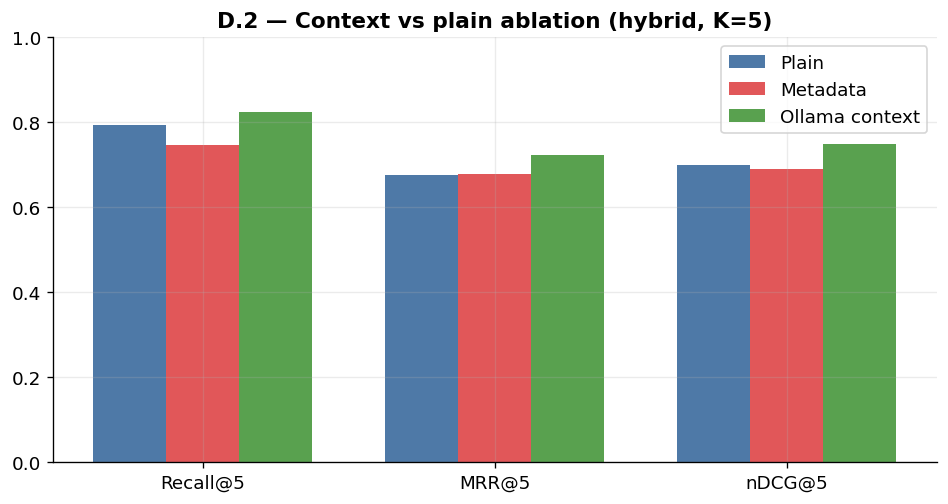

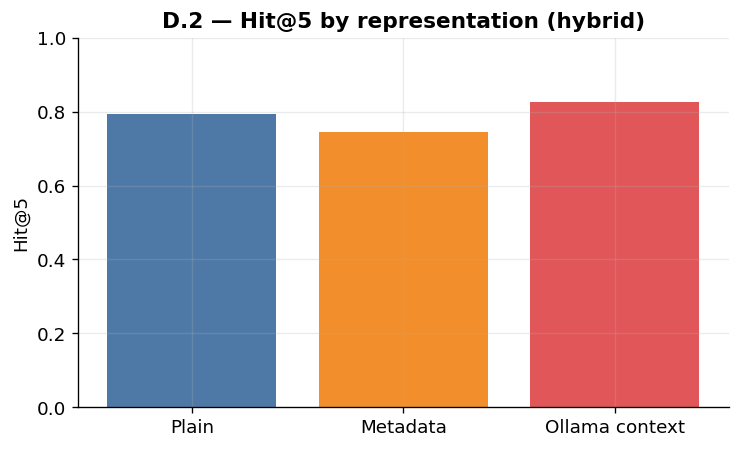

(                       condition    mode            source  n_queries  \
 Condition                                                               
 Plain                      plain  hybrid  collection_query         63   
 Metadata        metadata_context  hybrid  collection_query         63   
 Ollama context    ollama_context  hybrid  collection_query         63   
 
                 Recall@5   MRR@5  nDCG@5  category_accuracy_at_1  
 Condition                                                         
 Plain             0.7937  0.6757  0.6998                  0.6190  
 Metadata          0.7460  0.6783  0.6895                  0.6508  
 Ollama context    0.8254  0.7228  0.7481                  0.6508  ,
         condition    mode   Hit@5
 0           Plain   dense  0.6825
 1           Plain  hybrid  0.7937
 2        Metadata   dense  0.6508
 3        Metadata  hybrid  0.7460
 4  Ollama context   dense  0.6825
 5  Ollama context  hybrid  0.8254)

In [21]:
# D.2 Contextual ablation (K=5, collection queries, hybrid)
ctx = pd.read_csv(CTX / "summary_latest.csv")
coll = ctx[ctx["source"] == "collection_query"].copy()
label = {"plain":"Plain","metadata_context":"Metadata","ollama_context":"Ollama context"}
coll["Condition"] = coll["condition"].map(label)
hyb = coll[coll["mode"]=="hybrid"].set_index("Condition").loc[["Plain","Metadata","Ollama context"]]
hyb = hyb.rename(columns={"recall_at_k":"Recall@5","mrr_at_k":"MRR@5","ndcg_at_k":"nDCG@5"})
hyb.round(4).to_csv(FIG / "D2_contextual_ablation.csv")

# Hit@5 from per-query details (first relevant in top-K)
details = pd.read_csv(CTX / "paper_contextual_retrieval_eval_20260701_151729_details.csv")
sub = details[details["source"]=="collection_query"]
hit_rows = []
for cond in ["plain","metadata_context","ollama_context"]:
    for mode in ["dense","hybrid"]:
        d = sub[(sub["condition"]==cond)&(sub["mode"]==mode)]
        hit = (d["first_hit_rank"].notna() & (d["first_hit_rank"] <= 5)).mean()
        hit_rows.append({"condition":label[cond],"mode":mode,"Hit@5":hit})
hit_tbl = pd.DataFrame(hit_rows)
hit_tbl.round(4).to_csv(FIG / "D2_hit_at_5.csv", index=False)

metrics = ["Recall@5","MRR@5","nDCG@5"]
x = np.arange(3); w = 0.25
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for i, cond in enumerate(["Plain","Metadata","Ollama context"]):
    row = hyb.loc[cond]
    ax.bar(x+(i-1)*w, [row[m] for m in metrics], w, label=cond, color=PALETTE[i])
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0,1)
ax.legend(); ax.set_title("D.2 — Context vs plain ablation (hybrid, K=5)")
fig.savefig(FIG / "D2_ablation_hybrid.png"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
piv = hit_tbl[hit_tbl["mode"] == "hybrid"].set_index("condition")["Hit@5"]
ax.bar(piv.index, piv.values, color=[PALETTE[0],PALETTE[3],PALETTE[1]])
ax.set_ylim(0,1); ax.set_ylabel("Hit@5"); ax.set_title("D.2 — Hit@5 by representation (hybrid)")
fig.savefig(FIG / "D2_hit_at_5.png"); plt.show()
hyb.round(4), hit_tbl.round(4)


# Part E — Report Quality Evaluation

## Metric definitions (LLM-as-judge and RAGAS-style)

| Metric | Definition |
|--------|------------|
| **Faithfulness** | Generated claims are supported by the retrieved context and XAI evidence; no unsupported assertions. Higher is better (0–1). |
| **Answer relevancy** | Response addresses the screening-support question and case context. Higher is better. |
| **Hallucination rate** | Fraction of claims not grounded in provided context. **Lower is better.** |
| **Context precision** | Fraction of retrieved passages that are relevant to the question. Higher is better. |
| **Context recall** | Fraction of necessary information retrieved from the knowledge base. Higher is better. |

**Systems compared (RAG ablation):** S0 baseline → S3 full (local XAI + aggregated XAI + literature RAG).
Judge: GPT-4o-mini; generator: Ollama Llama 3. Three preset cases (high / low / borderline risk).


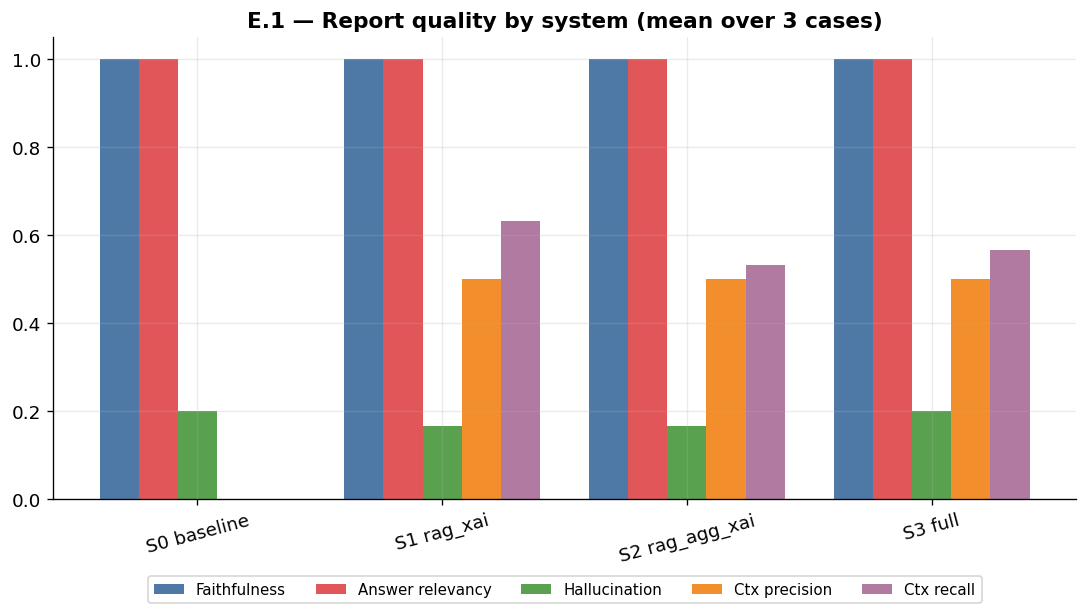

,faithfulness,answer_relevancy,hallucination_rate,context_precision,context_recall
System,,,,,
S0 baseline,1.0,1.0,0.200,NaN,NaN
S1 rag_xai,1.0,1.0,0.167,0.5,0.633
S2 rag_agg_xai,1.0,1.0,0.167,0.5,0.533
S3 full,1.0,1.0,0.200,0.5,0.567


In [ ]:
# E.1 End-to-end RAG ablation (per-system means)
rag = pd.read_csv(XAI / "rag_ablation_evaluation.csv")
sys_map = {"baseline":"S0 baseline","rag_xai":"S1 rag_xai",
           "rag_agg_xai":"S2 rag_agg_xai","full":"S3 full"}
rag["System"] = rag["system"].map(sys_map)
means = rag.groupby("System")[["faithfulness","answer_relevancy","hallucination_rate",
                                "context_precision","context_recall"]].mean().round(3)
means.to_csv(FIG / "E1_rag_ablation_means.csv")

metrics = ["faithfulness","answer_relevancy","hallucination_rate","context_precision","context_recall"]
mlabels = ["Faithfulness","Answer relevancy","Hallucination","Ctx precision","Ctx recall"]
x = np.arange(len(means)); w = 0.16
fig, ax = plt.subplots(figsize=(11, 5))
for i, (m, lab) in enumerate(zip(metrics, mlabels)):
    ax.bar(x+(i-2)*w, means[m].values, w, label=lab, color=PALETTE[i])
ax.set_xticks(x); ax.set_xticklabels(means.index, rotation=15)
ax.set_ylim(0, 1.05); ax.legend(ncol=5, bbox_to_anchor=(0.5,-0.15), loc="upper center", fontsize=9)
ax.set_title("E.1 — Report quality by system (mean over 3 cases)")
fig.savefig(FIG / "E1_rag_ablation.png"); plt.show()
means


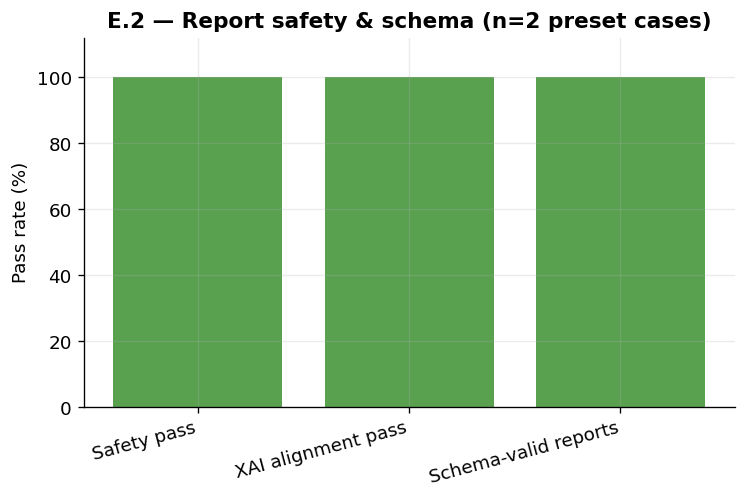

,Metric,Value,n
0,Safety pass,100%,2
1,XAI alignment pass,100%,2
2,Schema-valid reports,100%,2
3,Citations fully supported,25 / 32,32
4,Citations partially supported,7 / 32,32


In [ ]:
# E.2 Pipeline safety / schema pass rates (controlled smoke eval)
safety = pd.DataFrame({
    "Metric": ["Safety pass", "XAI alignment pass", "Schema-valid reports",
               "Citations fully supported", "Citations partially supported"],
    "Value": ["100%", "100%", "100%", "25 / 32", "7 / 32"],
    "n": [2, 2, 2, 32, 32],
})
safety.to_csv(FIG / "E2_safety_pass.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(safety["Metric"][:3], [100,100,100], color=PALETTE[2])
ax.set_ylim(0, 112); ax.set_ylabel("Pass rate (%)")
ax.set_title("E.2 — Report safety & schema (n=2 preset cases)")
plt.xticks(rotation=15, ha="right")
fig.savefig(FIG / "E2_safety.png"); plt.show()
safety


## Summary

All metric definitions and result figures are exported to `paper_outputs/metrics_figures/`.
For the full operational pipeline see `HMS_Results_Paper.ipynb` and `HMS_Dataset_Description_Paper.ipynb`.


In [ ]:
print("Exported figures and tables:")
for p in sorted(FIG.glob("*")):
    print(" ", p.name)
print(f"\nTotal artefacts: {len(list(FIG.glob('*')))}")


Exported figures and tables:
  A1_auc_by_model.png
  A1_metrics_grouped.png
  A2_bootstrap_ci.csv
  A2_bootstrap_ci.png
  A3_calibration.png
  A4_confusion_bootstrap_ci.csv
  A4_confusion_matrix.png
  B1_aggregated.png
  B1_aggregated_importance.csv
  B2_stability.csv
  B2_stability.png
  B3_faithfulness.csv
  B3_faithfulness.png
  B4_controls.png
  B4_faithfulness_controls.csv
  C1_level1.csv
  C1_level1.png
  C2_judge_heatmap.png
  C2_judge_overall.png
  C2_level2.csv
  D1_benchmark.png
  D1_retrieval_benchmark.csv
  D2_ablation_hybrid.png
  D2_contextual_ablation.csv
  D2_hit_at_5.csv
  D2_hit_at_5.png
  E1_rag_ablation.png
  E1_rag_ablation_means.csv
  E2_safety.png
  E2_safety_pass.csv
  ml_model_comparison.csv

Total artefacts: 31
